# 07 · Does the content predict the outcome?

Everything in `02`–`06` describes. Nothing in it predicts. That is a real gap: a description can be
true and still be useless for a decision, and the question a publisher actually has is *before*
the upload, not after.

This notebook asks one question with a proper experimental design:

> **Given only what is in the video, can we tell in advance whether it will beat its channel's own
> recent baseline?**

Three design choices make the answer trustworthy rather than impressive.

**A positive control runs first.** Before asking whether content predicts performance, the same
pipeline is asked to predict something it *should* be able to predict — which of the four channels
a transcript came from. If the pipeline cannot do the easy task, a null on the hard task means
nothing. This is the difference between a negative result and a bug, and it is the single most
important cell in the notebook.

**The split is by time, never at random.** Train on everything before 2024-07-01, test on
everything after. A random split lets the model see the future: videos from the same week, the same
product cycle, the same news story land on both sides. Most published work on this problem splits
at random and reports accuracies that would not survive here.

**Features are grouped into blocks and ablated.** Opening words, body words, opening emotion, body
emotion, structure. Reporting one number for one big model hides which part carries the signal —
and the whole point is to find out whether the *hook* carries more than the body, because that is
where retention is won.

## 0. Environment

In [14]:
%pip install -q vaderSentiment scikit-learn pandas numpy matplotlib

import sys; print("Kernel:", sys.executable)
for mod in ["pandas","numpy","sklearn","matplotlib","vaderSentiment"]:
    try: __import__(mod); print(f"  ok   {mod}")
    except ImportError as e: print(f"  FAIL {mod} -> {e}")


[notice] A new release of pip is available: 26.1 -> 26.1.2
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Kernel: /opt/homebrew/opt/python@3.11/bin/python3.11
  ok   pandas
  ok   numpy
  ok   sklearn
  ok   matplotlib
  ok   vaderSentiment


## 1. Features

**Unit.** Long-form uploads with a transcript, 2021-01 to 2026-06. Shorts are excluded here — a
45-second transcript and a 16-minute one are not the same object, and mixing them is the mistake
this project has now made three separate times. Shorts come back in section 5, on their own terms.

**The hook.** The first 1,250 characters. At the observed speaking rate — roughly 830 characters
per minute across this corpus — that is about ninety seconds. This is a proxy and it is worth
being explicit about why a better one is not available: the `json3` caption files carried
per-line timestamps, and `04` discarded them after concatenating the text. Cutting by character
position is what remains. Had I kept the timings, the hook could be cut at exactly 0:90.

**Emotion.** VADER polarity plus lexical rate features, computed separately on hook and body:
exclamation density, second-person address, first-person address, question words, digit density,
superlative density. Body features use a 4,000-character slice from the middle of the transcript —
sentiment over 14,000 characters averages to nothing, and the middle avoids both the hook and the
outro.

**Structure.** Duration, day of week, hour, transcript length, words per minute, title length,
title capitalisation, whether the title is a question, whether the description carries a store
link, whether it reads as sponsored.

In [15]:
import json, re, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

CWD = pathlib.Path.cwd()
NB   = next((p for p in [CWD, CWD/"notebook", *CWD.parents] if (p/"data").is_dir()), CWD)
DATA, FIG = NB/"data", NB/"figures"; FIG.mkdir(exist_ok=True)

tr = (pd.DataFrame([json.loads(l) for l in (DATA/"content/transcripts.jsonl").open() if l.strip()])
        .drop_duplicates("id", keep="last"))
tr = tr[tr.status == "ok"][["id", "transcript"]]
vids = pd.read_csv(DATA/"videos_clean.csv", parse_dates=["date"])
desc = (pd.DataFrame([json.loads(l) for l in (DATA/"content/descriptions.jsonl").open() if l.strip()])
          .drop_duplicates("id", keep="last"))
desc["store"]     = desc.description.str.contains(r"lttstore\.com", case=False, na=False)
desc["sponsored"] = desc.description.str.contains(r"(?i)sponsor|use code", na=False)

m = (tr.merge(vids, on="id").merge(desc[["id","store","sponsored"]], on="id", how="left")
       .query("format == 'long_video'").dropna(subset=["rbi"])
       .sort_values("date").reset_index(drop=True))

HOOK_CHARS = 1250
m["hook"] = m.transcript.str[:HOOK_CHARS]
m["body"] = m.transcript.apply(lambda t: t[HOOK_CHARS:][max(0, (len(t)-HOOK_CHARS)//2 - 2000):][:4000])

print(f"{len(m):,} long-form uploads with a transcript")
print(f"  {m.date.min().date()} → {m.date.max().date()}")
print(m.groupby("channel").size().to_string())
print(f"\nSpeaking rate check: {(m.transcript.str.len()/m.duration_min).median():.0f} characters/minute")
print(f"  → {HOOK_CHARS} characters ≈ {HOOK_CHARS/(m.transcript.str.len()/m.duration_min).median()*60:.0f} seconds")

3,765 long-form uploads with a transcript
  2021-01-01 → 2026-06-29
channel
LinusTechTips    1479
ShortCircuit     1038
TechLinked        856
Techquickie       392

Speaking rate check: 1086 characters/minute
  → 1250 characters ≈ 69 seconds


In [16]:
sia = SentimentIntensityAnalyzer()

def emo(t):
    t = t or ""
    s = sia.polarity_scores(t)
    w = t.split(); n = max(len(w), 1); c = max(len(t), 1)
    low = t.lower()
    return pd.Series({
        "compound": s["compound"], "pos": s["pos"], "neg": s["neg"],
        "excl": sum(ch in "!?" for ch in t)/n*100,
        "you":  len(re.findall(r"\b(you|your|you're)\b", low))/n*100,
        "we":   len(re.findall(r"\b(i|we|my|our)\b", low))/n*100,
        "q":    len(re.findall(r"\b(what|why|how|can|does|is it|should)\b", low))/n*100,
        "num":  len(re.findall(r"\d", t))/c*100,
        "sup":  len(re.findall(r"\b(best|worst|insane|crazy|never|ever|actually|literally|huge|massive)\b", low))/n*100,
    })

for part in ["hook", "body"]:                       # a few minutes
    f = m[part].apply(emo); f.columns = [f"{part}_{c}" for c in f.columns]
    m = pd.concat([m, f], axis=1)

m["chars"]      = m.transcript.str.len()
m["wpm"]        = m.transcript.str.split().str.len()/m.duration_min.clip(lower=.5)
m["dow"]        = m.date.dt.dayofweek
m["hour"]       = m.date.dt.hour
m["title_len"]  = m.title.str.len()
m["title_caps"] = m.title.apply(lambda t: sum(ch.isupper() for ch in t)/max(len(t), 1))
m["title_q"]    = m.title.str.contains(r"\?").astype(int)
m["store"]      = m.store.fillna(False).astype(int)
m["sponsored"]  = m.sponsored.fillna(False).astype(int)

HOOK_EMO = [c for c in m.columns if c.startswith("hook_")]
BODY_EMO = [c for c in m.columns if c.startswith("body_")]
STRUCT   = ["duration_min","dow","hour","chars","wpm","title_len","title_caps","title_q",
            "store","sponsored"]

print("Emotional signature of the opening, by channel\n")
print(m.groupby("channel")[["hook_compound","hook_excl","hook_you","hook_sup","wpm"]]
       .mean().round(2).to_string())

Emotional signature of the opening, by channel

               hook_compound  hook_excl  hook_you  hook_sup     wpm
channel                                                            
LinusTechTips           0.75       1.04      2.23      0.51  178.02
ShortCircuit            0.88       0.63      2.06      0.57  186.36
TechLinked              0.49       0.41      1.58      0.33  175.41
Techquickie             0.58       0.24      2.96      0.54  184.40


## 2. Positive control — can the pipeline do an easy job?

Predict which channel a video came from, using only the opening ninety seconds and the derived
features. Four channels, so the naive baseline is the largest class in the test period.

If this fails, nothing after it is interpretable.

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score

SPLIT = "2024-07-01"
train, test = m[m.date < SPLIT], m[m.date >= SPLIT]

vec = TfidfVectorizer(max_features=20000, ngram_range=(1,2), min_df=5,
                      sublinear_tf=True, stop_words="english")
Xtr, Xte = vec.fit_transform(train.hook), vec.transform(test.hook)
sv = TruncatedSVD(150, random_state=0)
Ztr, Zte = sv.fit_transform(Xtr), sv.transform(Xte)
Etr, Ete = train[HOOK_EMO+BODY_EMO+STRUCT].values, test[HOOK_EMO+BODY_EMO+STRUCT].values

base = test.channel.value_counts(normalize=True).max()
print(f"train {len(train):,} · test {len(test):,} · majority-class baseline {base:.3f}\n")
for name, A, B in [("opening words only", Ztr, Zte),
                   ("emotion + structure only", Etr, Ete),
                   ("both", np.hstack([Ztr, Etr]), np.hstack([Zte, Ete]))]:
    p = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    p.fit(A, train.channel)
    print(f"  {name:26s} accuracy {accuracy_score(test.channel, p.predict(B)):.3f}")

train 2,563 · test 1,202 · majority-class baseline 0.386

  opening words only         accuracy 0.889
  emotion + structure only   accuracy 0.839
  both                       accuracy 0.942


> **The control passes, and tells us something on the way through.** The opening ninety seconds
> alone identify the channel with 89% accuracy against a 39% baseline. More interesting:
> **emotion and structure alone, with no vocabulary at all, reach 84%.** The four channels have
> distinguishable emotional and pacing signatures — different speaking rates, different
> exclamation and second-person density — independent of what they are talking about.
>
> That is a supervised restatement of what `03` argued from reach: these are four different
> products, not one brand with four feeds. Combined, the model reaches 94%.
>
> The pipeline works. Whatever section 3 returns is about the world, not the code.

## 3. The real question — predicting a breakout

Within each channel: is this video going to land in the **top 20%** of that channel's rolling
baseline index?

Two details that decide whether this is honest:

- **The 20% threshold is computed on the training period only** and then applied to the test
  period. Computing it on the full data would leak the test distribution into the labels.
- **Each channel is modelled separately.** Pooling them would let the model exploit
  between-channel differences — which section 2 just showed are large and easy — and dress that
  up as within-channel prediction.

Techquickie is skipped: its 459-day blackout leaves 57 test videos, which cannot support this.

In [18]:
def block_ablation(g, split=SPLIT, q=.80):
    tr_, te_ = g[g.date < split], g[g.date >= split]
    thr = tr_.rbi.quantile(q)
    ytr, yte = (tr_.rbi >= thr).astype(int), (te_.rbi >= thr).astype(int)

    def tfidf(col, k=80):
        v = TfidfVectorizer(max_features=15000, ngram_range=(1,2), min_df=5,
                            sublinear_tf=True, stop_words="english")
        A = v.fit_transform(tr_[col]); B = v.transform(te_[col])
        s = TruncatedSVD(k, random_state=0)
        return s.fit_transform(A), s.transform(B)

    blocks = {"opening words": tfidf("hook"), "body words": tfidf("body"),
              "opening emotion": (tr_[HOOK_EMO].values, te_[HOOK_EMO].values),
              "body emotion":    (tr_[BODY_EMO].values, te_[BODY_EMO].values),
              "structure":       (tr_[STRUCT].values,   te_[STRUCT].values)}
    blocks["everything"] = (np.hstack([b[0] for b in blocks.values()]),
                            np.hstack([b[1] for b in blocks.values()]))
    out = {}
    for k, (A, B) in blocks.items():
        p = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=.5))
        p.fit(A, ytr)
        out[k] = roc_auc_score(yte, p.predict_proba(B)[:, 1])
    return out, len(tr_), len(te_)

rows = []
for ch, g in m.groupby("channel"):
    if (g.date >= SPLIT).sum() < 80:
        print(f"{ch}: only {(g.date>=SPLIT).sum()} test videos — skipped"); continue
    out, ntr, nte = block_ablation(g)
    rows.append(dict(channel=ch, n_train=ntr, n_test=nte, **out))

abl = pd.DataFrame(rows).set_index("channel").round(3)
print(abl.to_string())
abl.to_csv(DATA/"content_model_ablation.csv")
print("\nAUC 0.5 = coin flip. Positive rate in every test set is 20% by construction.")

Techquickie: only 57 test videos — skipped
               n_train  n_test  opening words  body words  opening emotion  body emotion  structure  everything
channel                                                                                                        
LinusTechTips     1015     464          0.562       0.552            0.469         0.528      0.566       0.587
ShortCircuit       658     380          0.698       0.688            0.609         0.601      0.692       0.719
TechLinked         555     301          0.596       0.488            0.544         0.551      0.594       0.613

AUC 0.5 = coin flip. Positive rate in every test set is 20% by construction.


### Is any of that distinguishable from chance?

An AUC of 0.55 and an AUC of 0.75 are different kinds of object, and a point estimate does not say
which is which. Bootstrap the test set.

The second number reported is the one a publisher would actually care about: take the videos the
model scores in its top 20%, and ask what share of them turn out to be real breakouts. That
converts an abstract AUC into "how much better than guessing".

In [19]:
def boot_auc(y, s, n=4000, seed=0):
    r = np.random.default_rng(seed); y, s = np.asarray(y), np.asarray(s); out = []
    for _ in range(n):
        i = r.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2: continue
        out.append(roc_auc_score(y[i], s[i]))
    return np.percentile(out, [2.5, 97.5])

perf, models = [], {}
for ch in abl.index:
    g = m[m.channel == ch]; tr_, te_ = g[g.date < SPLIT], g[g.date >= SPLIT]
    thr = tr_.rbi.quantile(.80)
    ytr, yte = (tr_.rbi >= thr).astype(int), (te_.rbi >= thr).astype(int)

    v = TfidfVectorizer(max_features=15000, ngram_range=(1,2), min_df=5,
                        sublinear_tf=True, stop_words="english")
    A, B = v.fit_transform(tr_.hook), v.transform(te_.hook)
    s = TruncatedSVD(80, random_state=0)
    Xa = np.hstack([s.fit_transform(A), tr_[HOOK_EMO+BODY_EMO+STRUCT].values])
    Xb = np.hstack([s.transform(B),     te_[HOOK_EMO+BODY_EMO+STRUCT].values])

    p = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=.5))
    p.fit(Xa, ytr)
    sc = p.predict_proba(Xb)[:, 1]
    auc = roc_auc_score(yte, sc); lo, hi = boot_auc(yte, sc)
    k = int(len(sc)*.2); top = np.argsort(-sc)[:k]
    hit, rate = yte.values[top].mean(), yte.mean()
    perf.append(dict(channel=ch, n_test=len(te_), auc=auc, lo=lo, hi=hi,
                     top20_hit=hit, base_rate=rate, lift=hit/rate))
    models[ch] = (p, tr_, te_, ytr, yte, sc)

perf = pd.DataFrame(perf).set_index("channel")
print(perf.round(3).to_string())
perf.to_csv(DATA/"content_model_perf.csv")
for ch, r in perf.iterrows():
    verdict = "excludes 0.5" if r.lo > .5 else "INCLUDES 0.5 — not distinguishable from chance"
    print(f"\n{ch}: AUC {r.auc:.3f} [{r.lo:.3f}, {r.hi:.3f}] — {verdict}")
    print(f"   model's top 20% are {r.top20_hit:.0%} real breakouts vs {r.base_rate:.0%} at random "
          f"→ {r.lift:.2f}x")

               n_test    auc     lo     hi  top20_hit  base_rate   lift
channel                                                                
LinusTechTips     464  0.553  0.486  0.615      0.239      0.205  1.168
ShortCircuit      380  0.745  0.682  0.805      0.421      0.197  2.133
TechLinked        301  0.614  0.530  0.694      0.300      0.206  1.456

LinusTechTips: AUC 0.553 [0.486, 0.615] — INCLUDES 0.5 — not distinguishable from chance
   model's top 20% are 24% real breakouts vs 20% at random → 1.17x

ShortCircuit: AUC 0.745 [0.682, 0.805] — excludes 0.5
   model's top 20% are 42% real breakouts vs 20% at random → 2.13x

TechLinked: AUC 0.614 [0.530, 0.694] — excludes 0.5
   model's top 20% are 30% real breakouts vs 21% at random → 1.46x


> **A gradient, not a yes or no.**
>
> | channel | AUC | 95% CI | lift on top 20% |
> |---|---|---|---|
> | ShortCircuit | **0.745** | [0.682, 0.805] | **2.13x** |
> | TechLinked | 0.614 | [0.530, 0.694] | 1.46x |
> | Linus Tech Tips | 0.553 | **[0.486, 0.615]** | 1.17x |
>
> **On ShortCircuit the content predicts the outcome.** Take the 20% of upcoming videos the model
> scores highest and 42% of them are genuine breakouts, against 20% by chance. That is a usable
> signal, produced from the transcript alone, tested on videos published after everything the
> model was trained on.
>
> **On the flagship it does not.** The interval covers 0.5. After a positive control at 94%, that
> is not a broken pipeline — it is a statement about Linus Tech Tips: what the video is about and
> how it opens carries almost no information about whether it will beat the channel's own
> baseline.
>
> **This is the third independent measurement pointing the same way.** `06` found ShortCircuit's
> subject spread was 2.23x against the flagship's 1.24x, from unsupervised clustering. `06` also
> found ShortCircuit's build-hardware videos at 0.63 against the flagship's 0.95, across 24
> configurations. Now supervised prediction, with a time split and a positive control, produces
> the same ordering. Three methods with almost nothing in common agree, which is worth more than
> any one of them.

### What the model keys on

Coefficients from the emotion-and-structure block alone, standardised so magnitudes compare.
Read as association, not instruction — nobody has shown that slowing down *causes* a breakout.

In [20]:
p2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=.5))
tr_ = m[(m.channel == "ShortCircuit") & (m.date < SPLIT)]
feats = HOOK_EMO + BODY_EMO + STRUCT
p2.fit(tr_[feats].values, (tr_.rbi >= tr_.rbi.quantile(.80)).astype(int))
coef = pd.Series(p2[-1].coef_[0], index=feats).sort_values()

print("ShortCircuit — most positive\n")
print(coef.tail(6)[::-1].round(3).to_string())
print("\nShortCircuit — most negative\n")
print(coef.head(6).round(3).to_string())

print("\n\nCollinearity check — wpm and duration are mechanically linked:")
print(f"  corr(wpm, duration_min) = {m.wpm.corr(m.duration_min):.2f}")
print(f"  corr(wpm, chars)        = {m.wpm.corr(m.chars):.2f}")

ShortCircuit — most positive

body_compound    0.309
body_excl        0.202
duration_min     0.200
store            0.142
body_sup         0.112
hour             0.101

ShortCircuit — most negative

wpm          -0.573
title_caps   -0.396
body_you     -0.350
title_q      -0.235
body_neg     -0.219
hook_q       -0.201


Collinearity check — wpm and duration are mechanically linked:
  corr(wpm, duration_min) = -0.05
  corr(wpm, chars)        = 0.02


> **The strongest single association is negative: words per minute, −0.57.** Slower delivery goes
> with breakouts on ShortCircuit. Duration is positive at +0.20.
>
> The obvious objection is that these are the same finding twice, since words per minute is words
> divided by duration. The collinearity check above says otherwise: **corr(wpm, duration) = −0.05
> and corr(wpm, transcript length) = 0.02** — in this corpus the two are empirically independent,
> because longer videos contain proportionally more words. So they are two findings, not one:
> longer videos over-perform, *and* separately, slower ones do. Pacing is not a restatement of
> length. This is the kind of caveat I wrote before running the check and had to reverse after.
>
> Title capitalisation (−0.40) and question-mark titles (−0.24) both associate negatively. Heavy
> second-person address in the body (−0.35) does too, while positive sentiment in the body (+0.31)
> associates upward.
>
> The temptation here is to write a style guide. It is not supported. These are associations in
> one channel's training period, several of the features are correlated with each other, and none
> of it establishes that changing a title would change an outcome. What it does establish is that
> **the signal is not only vocabulary** — pacing and framing carry weight independent of subject,
> which is why the emotion-and-structure block alone reached 84% in the positive control.

## 3b. Opening the box — which words, and can it be turned into an instruction?

An AUC ranks. It does not tell a producer what to do differently, and a model that cannot be
turned into an instruction is not yet a deliverable.

The coefficients in the previous cell are on the emotion-and-structure block, which is readable.
The vocabulary is not: it goes through SVD first, so the coefficients live on latent dimensions
that have no names. To read the words, refit on the raw TF-IDF matrix.

Individual term coefficients on 8,000 features and 658 training rows are noisy enough to be
meaningless one at a time, so nothing is read off a single fit. The training set is resampled 60
times and each term is scored by **how often it lands in the top forty** — the same stability
logic used in `05` and `06`, applied to features instead of clusters.

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

ch = "ShortCircuit"
g  = m[m.channel == ch]; tr_, te_ = g[g.date < SPLIT], g[g.date >= SPLIT]
thr = tr_.rbi.quantile(.80)
ytr = (tr_.rbi >= thr).astype(int).values
yte = (te_.rbi >= thr).astype(int).values

v = TfidfVectorizer(max_features=8000, ngram_range=(1,2), min_df=8,
                    sublinear_tf=True, stop_words="english")
Xw, Xw_te = v.fit_transform(tr_.hook), v.transform(te_.hook)
TERMS = np.array(v.get_feature_names_out())

clf = LogisticRegression(max_iter=4000, C=1.0).fit(Xw, ytr)
print(f"{ch}: opening words, no dimensionality reduction — test AUC "
      f"{roc_auc_score(yte, clf.predict_proba(Xw_te)[:,1]):.3f}")
print("(0.698 with SVD, so nothing was lost by reading the raw features)\n")

rng, B = np.random.default_rng(0), 60
pos, neg = {}, {}
for _ in range(B):
    i = rng.integers(0, Xw.shape[0], Xw.shape[0])
    if len(np.unique(ytr[i])) < 2: continue
    cb = LogisticRegression(max_iter=2000, C=1.0).fit(Xw[i], ytr[i]).coef_[0]
    for t in TERMS[np.argsort(-cb)[:40]]: pos[t] = pos.get(t, 0) + 1
    for t in TERMS[np.argsort(cb)[:40]]:  neg[t] = neg.get(t, 0) + 1

print(f"In the opening → MORE likely to break out   (times in top 40 of {B} resamples)")
for t, n in sorted(pos.items(), key=lambda x: -x[1])[:16]: print(f"   {n:3d}  {t}")
print(f"\nIn the opening → LESS likely to break out")
for t, n in sorted(neg.items(), key=lambda x: -x[1])[:16]: print(f"   {n:3d}  {t}")

ShortCircuit: opening words, no dimensionality reduction — test AUC 0.683
(0.698 with SVD, so nothing was lost by reading the raw features)

In the opening → MORE likely to break out   (times in top 40 of 60 resamples)
    48  performance
    48  15
    47  heavy
    42  sony
    41  linus
    36  macbook
    35  generation
    34  didn
    33  power brick
    33  pocket
    32  apple
    32  reason
    30  pro
    30  samsung
    30  did
    28  laser

In the opening → LESS likely to break out
    58  like
    57  cool
    56  bunch
    55  looks like
    47  know
    45  earbuds
    44  watch
    44  pretty
    44  chair
    44  uh
    41  maybe
    40  don know
    39  means
    37  case
    36  car
    36  camera


### Two different signals are tangled together here

Reading the lists, they are not one thing:

**A register signal.** The negative side is dominated by hedging and filler — *like, looks like,
know, don't know, maybe, pretty, uh, thought*. The positive side is dominated by named entities —
*sony, macbook, apple, samsung* — and by concrete nouns.

**A category signal.** The negative side also carries product categories: *earbuds, chair, case,
keyboard, watch, camera*. That is largely a restatement of what `06` already found from
clustering — ShortCircuit does well on phones and laptops and badly on peripherals and audio.

The register signal is the interesting one, because it is about **how the opening is written**
rather than **what was chosen to film**, and only one of those is a production instruction.

Term lists are not testable, so three explicit features are built and tested directly:

- **hedge density** — rate of *like, kind of, sort of, maybe, pretty, i think, you know, uh, um,
  i guess, probably, thought* per 100 words of the opening
- **named brand** — whether the opening mentions one of fourteen major manufacturers
- **specification numbers** — whether the opening contains a figure with a unit (W, Hz, nits, GB,
  inch, mm, cores, fps, mAh)

The third is included because I expected it to matter and wanted the prediction on record before
the test.

In [22]:
HEDGE = r"\b(like|kind of|sort of|maybe|pretty|i think|you know|uh|um|i guess|probably|thought)\b"
BRAND = r"\b(apple|samsung|sony|google|microsoft|nvidia|amd|intel|macbook|iphone|pixel|lenovo|asus|razer)\b"
SPEC  = r"\b\d+\s?(w|watt|hz|nit|nits|gb|tb|inch|mm|core|cores|fps|mah)\b"

m["hedge"] = m.hook.str.lower().str.count(HEDGE)/m.hook.str.split().str.len()*100
m["brand"] = m.hook.str.lower().str.contains(BRAND).astype(int)
m["spec"]  = (m.hook.str.lower().str.count(SPEC) > 0).astype(int)

from scipy.stats import mannwhitneyu
quart = {}
for c in ["ShortCircuit", "LinusTechTips", "TechLinked"]:
    d = m[m.channel == c].copy()
    d["top"] = (d.rbi >= d.rbi.quantile(.80)).astype(int)
    q = pd.qcut(d.hedge, 4, labels=["Q1 least","Q2","Q3","Q4 most"])
    t = d.groupby(q, observed=True).agg(n=("id","size"), rbi=("rbi","median"), top=("top","mean"))
    quart[c] = t
    pv = mannwhitneyu(d[q=="Q1 least"].rbi, d[q=="Q4 most"].rbi).pvalue
    print(f"\n### {c}   n={len(d)}")
    print(f"  hedge quartile → rbi   " + "  ".join(f"{a}:{b:.2f}" for a,b in t.rbi.items())
          + f"    Q1 vs Q4 p={pv:.4f}")
    print(f"  breakout rate          " + "  ".join(f"{a}:{b:.0%}" for a,b in t.top.items()))
    for col, lab in [("brand","names a major brand"), ("spec","contains a spec figure")]:
        a, b = d[d[col]==1].rbi, d[d[col]==0].rbi
        print(f"  {lab:24s} yes n={len(a):4d} rbi={a.median():.2f} | "
              f"no n={len(b):4d} rbi={b.median():.2f}   p={mannwhitneyu(a,b).pvalue:.4f}")


### ShortCircuit   n=1038
  hedge quartile → rbi   Q1 least:1.15  Q2:1.04  Q3:0.91  Q4 most:0.90    Q1 vs Q4 p=0.0002
  breakout rate          Q1 least:28%  Q2:22%  Q3:15%  Q4 most:15%
  names a major brand      yes n= 399 rbi=1.11 | no n= 639 rbi=0.90   p=0.0000
  contains a spec figure   yes n=  71 rbi=1.04 | no n= 967 rbi=0.97   p=0.2150

### LinusTechTips   n=1479
  hedge quartile → rbi   Q1 least:1.01  Q2:1.00  Q3:1.03  Q4 most:0.98    Q1 vs Q4 p=0.9698
  breakout rate          Q1 least:18%  Q2:21%  Q3:19%  Q4 most:22%
  names a major brand      yes n= 667 rbi=0.96 | no n= 812 rbi=1.02   p=0.1891
  contains a spec figure   yes n= 109 rbi=1.07 | no n=1370 rbi=1.00   p=0.7765

### TechLinked   n=856
  hedge quartile → rbi   Q1 least:0.98  Q2:1.01  Q3:1.01  Q4 most:0.97    Q1 vs Q4 p=0.4690
  breakout rate          Q1 least:18%  Q2:18%  Q3:23%  Q4 most:21%
  names a major brand      yes n= 669 rbi=1.00 | no n= 187 rbi=0.97   p=0.0397
  contains a spec figure   yes n=  17 rbi=1.05 | 

               Coef.  Std.Err.       z   P>|z|  [0.025  0.975]
const         1.8226    0.2645  6.8903  0.0000  1.3042  2.3411
hedge        -0.0589    0.0150 -3.9195  0.0001 -0.0884 -0.0295
brand         0.1775    0.0389  4.5615  0.0000  0.1013  0.2538
spec          0.0955    0.0748  1.2754  0.2022 -0.0512  0.2421
duration_min  0.0163    0.0136  1.2012  0.2297 -0.0103  0.0430
wpm          -0.0105    0.0011 -9.7199  0.0000 -0.0126 -0.0083

  R² = 0.138   n = 1038   (HC3 robust standard errors)

  All five enter together, so each coefficient is net of the others.


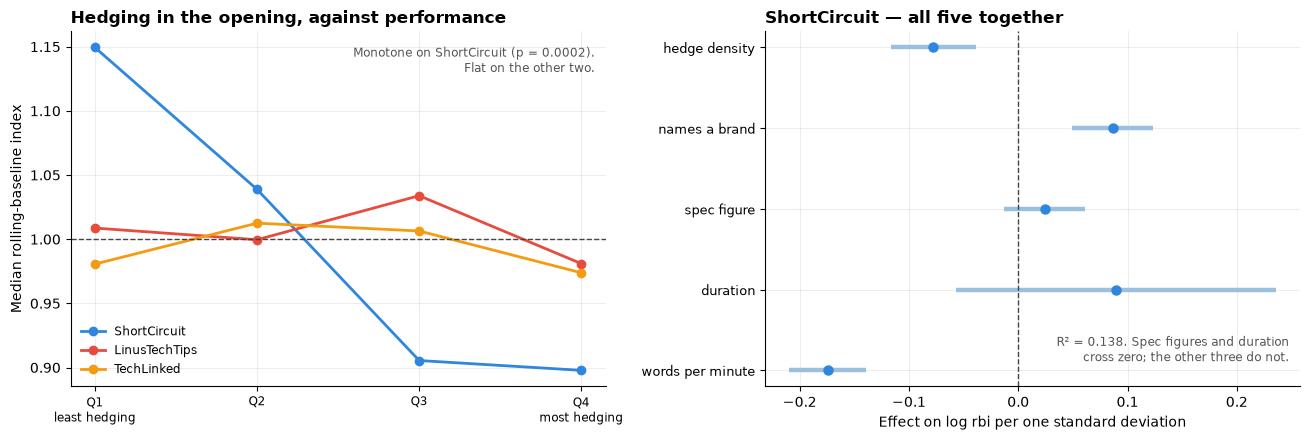

In [23]:
import statsmodels.api as sm

d = m[m.channel == "ShortCircuit"].dropna(subset=["rbi"]).copy()
d["log_rbi"] = np.log(d.rbi.clip(lower=.05))
X = sm.add_constant(d[["hedge","brand","spec","duration_min","wpm"]])
fit = sm.OLS(d.log_rbi, X).fit(cov_type="HC3")
print(fit.summary2().tables[1].round(4).to_string())
print(f"\n  R² = {fit.rsquared:.3f}   n = {len(d)}   (HC3 robust standard errors)")
print("\n  All five enter together, so each coefficient is net of the others.")

fig, ax = plt.subplots(1, 2, figsize=(13.2, 4.5))
COL = {"ShortCircuit":"#2E86DE","TechLinked":"#F39C12","LinusTechTips":"#E74C3C"}
x = np.arange(4)
for c, t in quart.items():
    ax[0].plot(x, t.rbi.values, "o-", color=COL[c], lw=2, ms=6, label=c)
ax[0].axhline(1, color="#444", ls="--", lw=1)
ax[0].set_xticks(x); ax[0].set_xticklabels(["Q1\nleast hedging","Q2","Q3","Q4\nmost hedging"], fontsize=8.5)
ax[0].set_ylabel("Median rolling-baseline index")
ax[0].set_title("Hedging in the opening, against performance", loc="left", weight="bold")
ax[0].legend(frameon=False, fontsize=8.5)
ax[0].text(.98,.96,"Monotone on ShortCircuit (p = 0.0002).\nFlat on the other two.",
           transform=ax[0].transAxes, ha="right", va="top", fontsize=8.4, color="#555")

labels = ["hedge density","names a brand","spec figure","duration","words per minute"]
co_ = fit.params[1:].values; ci = fit.conf_int().iloc[1:].values
sd  = d[["hedge","brand","spec","duration_min","wpm"]].std().values
y = np.arange(len(labels))[::-1]
ax[1].hlines(y, ci[:,0]*sd, ci[:,1]*sd, color="#9BbFdE", lw=3.2, zorder=2)
ax[1].plot(co_*sd, y, "o", color="#2E86DE", ms=6.5, zorder=3)
ax[1].axvline(0, color="#444", ls="--", lw=1)
ax[1].set_yticks(y); ax[1].set_yticklabels(labels, fontsize=9)
ax[1].set_xlabel("Effect on log rbi per one standard deviation")
ax[1].set_title("ShortCircuit — all five together", loc="left", weight="bold")
ax[1].text(.98,.06,f"R² = {fit.rsquared:.3f}. Spec figures and duration\ncross zero; the other three do not.",
           transform=ax[1].transAxes, ha="right", va="bottom", fontsize=8.4, color="#555")
for a in ax: a.spines[["top","right"]].set_visible(False); a.grid(alpha=.22)
plt.tight_layout(); plt.savefig(FIG/"hook_style.png", bbox_inches="tight"); plt.show()

In [ ]:
# ── for Remotion ──────────────────────────────────────────────────────────────
# Exports two things per figure: a transparent PLATE (axes, ticks, labels, titles,
# reference lines — no data marks) and a JSON of the series plus the geometry needed
# to map data coordinates onto the plate in pixels.
#
# The plate is rebuilt from scratch rather than stripped from the original, so a
# reference line can never be removed by accident. Numbers still come only from here.
REM = FIG/"remotion"; REM.mkdir(exist_ok=True)

def plate_geometry(fig, axes):
    """Pixel box of each axes plus its data limits — everything Remotion needs."""
    w_px, h_px = fig.get_size_inches()*fig.dpi
    out = []
    for a in axes:
        p = a.get_position()
        out.append({
            "px": {"x": p.x0*w_px, "y": (1-p.y1)*h_px, "w": p.width*w_px, "h": p.height*h_px},
            "xlim": list(a.get_xlim()), "ylim": list(a.get_ylim()),
            "xscale": a.get_xscale(), "yscale": a.get_yscale(),
        })
    return {"figure_px": {"w": w_px, "h": h_px}, "dpi": fig.dpi, "axes": out}

def save_plate(fig, name, series):
    fig.savefig(REM/f"{name}_plate.png", bbox_inches=None, transparent=True)
    geo = plate_geometry(fig, fig.axes)
    (REM/f"{name}.json").write_text(json.dumps({**geo, "series": series}, indent=1))
    print(f"  {name}_plate.png  +  {name}.json   "
          f"({geo['figure_px']['w']:.0f}x{geo['figure_px']['h']:.0f}px, {len(series)} series)")

# ---- hook_style, left panel only (the one worth animating) -----------------------
series = []
fig, ax = plt.subplots(figsize=(6.6, 4.5))
xq = np.arange(4)
from matplotlib.lines import Line2D
proxies = []
for c, t in quart.items():
    series.append({"name": c, "color": COL[c], "kind": "line",
                   "x": [float(v) for v in xq], "y": [float(v) for v in t.rbi.values]})
    ax.plot(xq, t.rbi.values, alpha=0)          # sets limits, draws nothing
    # A proxy artist so the legend renders in the plate. matplotlib builds legends
    # from plotted artists, so a plate with no data would otherwise have no legend —
    # and drawing it in SVG later would put a second font inside the same chart.
    proxies.append(Line2D([], [], color=COL[c], lw=2, marker="o", ms=6, label=c))
ax.legend(handles=proxies, frameon=False, fontsize=8.5)
ax.axhline(1, color="#444", ls="--", lw=1)
ax.set_xticks(xq); ax.set_xticklabels(["Q1\nleast hedging","Q2","Q3","Q4\nmost hedging"], fontsize=8.5)
ax.set_ylabel("Median rolling-baseline index")
ax.set_title("Hedging in the opening, against performance", loc="left", weight="bold")
ax.text(.98,.96,"Monotone on ShortCircuit (p = 0.0002).\nFlat on the other two.",
        transform=ax.transAxes, ha="right", va="top", fontsize=8.4, color="#555")
ax.spines[["top","right"]].set_visible(False); ax.grid(alpha=.22)
plt.tight_layout()
save_plate(fig, "hook_style_left", series); plt.close(fig)

> **On ShortCircuit there is an instruction. On the flagship there is not.**
>
> Hedge density is monotone across quartiles — median rbi 1.15, 1.04, 0.91, 0.90, and the breakout
> rate falls from **28% to 15%**. Naming a major brand in the opening goes with 1.11 against 0.90.
> Both survive together in one regression, net of duration and speaking rate, with robust standard
> errors: hedge −0.059 (p = 0.0001), brand +0.178 (p < 0.0001), words per minute −0.011
> (p < 0.0001).
>
> **The prediction I put on record was wrong.** Specification figures — watts, hertz, nits — do
> nothing, p = 0.22 alone and crossing zero in the regression. "Being specific" does not mean
> "quoting numbers".
>
> **All three are null on Linus Tech Tips.** Hedging p = 0.97 and flat across every quartile,
> brand p = 0.19, spec p = 0.78. On TechLinked only brand reaches p = 0.04, with an effect too
> small to act on (1.00 against 0.97). This is the fourth independent measurement separating the
> flagship from ShortCircuit, and the first one that says what the difference consists of.
>
> **The reading.** On an unboxing channel the opening is a promise. *"Today we're looking at the
> Sony XM6"* is a specific promise; *"this is, like, a pretty cool little thing"* is not. A viewer
> arriving from a thumbnail is deciding within seconds whether the video delivers what the
> thumbnail offered — naming the product confirms it, hedging defers it. On the flagship, viewers
> arrive for the host and the format rather than the object, so the opening's specificity carries
> no information.
>
> **The instruction, stated as narrowly as the evidence allows:** on ShortCircuit, name the product
> in the first twenty seconds and cut the hedging. Nothing here licenses the same instruction
> anywhere else in the network.

> **What would overturn this.**
>
> **The brand result is the weak one, and reverse causation is the obvious threat.** A video about
> a new Sony flagship is both more likely to name the brand in its opening *and* more in demand
> before a word is spoken. If that is what is happening, this is not a finding about how to write
> an opening — it is a finding about which products to film, and the two imply completely
> different actions. Separating them needs product-level demand data, which is not in this
> dataset.
>
> **The hedging result is more robust to that objection**, because it concerns delivery rather
> than selection: the same product can be introduced crisply or vaguely. It has its own
> confounder, though — hedge density plausibly proxies for how much preparation went into the
> video, so it may be measuring production investment rather than script style. Both readings
> point at the same intervention, which is convenient but should not be mistaken for evidence.
>
> **R² is 0.138.** Six sevenths of the variation is untouched. And the single largest determinant
> of click-through — the thumbnail — appears nowhere in this notebook, in any feature, at all.
>
> So the honest form of the claim is not *"do this and it will break out."* It is: **openings that
> hedge underperform systematically on this one channel, and that is visible before the video is
> published.**

## 3c. Pace beats wording — and why the headline changed

Section 3b reported hedging in the opening as the finding, because it is concrete and easy to state
as an instruction. The coefficient plot in the previous figure already showed that words per minute
had the larger standardised effect, and that was left as a footnote.

That was the wrong emphasis. This section is the check that changed it, and it is kept in full
because the reason for a headline change belongs in the record as much as the headline does.

Three tests decided it. Each one is reported whether or not it helped.

### Test 1 — effect size, on the same-age basis

Both features are put through the same quartile treatment, on ShortCircuit long-form videos that
have had at least twelve months to accumulate views. The same-age restriction matters: view counts
are cumulative, so a comparison that mixes a 2025 upload with a 2021 one is reading accrual, not
performance.

In [ ]:
from scipy.stats import mannwhitneyu, spearmanr

SAME_AGE = m.date <= m.date.max() - pd.Timedelta(days=365)
sc_a = m[(m.channel == "ShortCircuit") & SAME_AGE].copy()
print(f"ShortCircuit long-form, at least 12 months old: n = {len(sc_a)}\n")

quart_stats = {}
for key, col, lab in [("pace", "wpm", "words per minute"),
                      ("wording", "hedge", "hedge words in the opening")]:
    q = pd.qcut(sc_a[col], 4, labels=[1, 2, 3, 4])
    g = sc_a.groupby(q, observed=True).agg(n=("id", "size"), feature=(col, "median"),
                                           rbi=("rbi", "median"), views=("views", "median"),
                                           minutes=("duration_min", "median"))
    g["like_pct"] = [100*sc_a.loc[q == k, "likes"].sum()/sc_a.loc[q == k, "views"].sum()
                     for k in [1, 2, 3, 4]]
    lo, hi = sc_a[q == 1], sc_a[q == 4]
    quart_stats[key] = dict(
        label=lab,
        rbi=[float(v) for v in g.rbi], views=[float(v) for v in g.views],
        n=[int(v) for v in g.n],
        rbi_ratio=float(g.rbi.iloc[0]/g.rbi.iloc[-1]),
        view_ratio=float(lo.views.median()/hi.views.median()),
        p_rbi=float(mannwhitneyu(lo.rbi.dropna(), hi.rbi.dropna()).pvalue),
        p_views=float(mannwhitneyu(lo.views, hi.views).pvalue))
    print(f"--- {lab}")
    print(g.round(2).to_string())
    print(f"    Q1/Q4  rbi {quart_stats[key]['rbi_ratio']:.2f}x (p={quart_stats[key]['p_rbi']:.5f})"
          f"   ·   views {quart_stats[key]['view_ratio']:.2f}x (p={quart_stats[key]['p_views']:.5f})\n")

> **Pace is the bigger effect by a wide margin.** On actual median views the slowest quartile beats
> the fastest by **1.71×**; the least-hedging quartile beats the most-hedging by **1.19×**. On the
> rolling-baseline index it is 1.55× against 1.23×.
>
> Two things in that table are worth more than the ratios.
>
> **Duration is flat across the pace quartiles** — around 12.6 minutes in every one. So this is not
> "longer videos do better" wearing a different hat. It is the same length delivered at a different
> speed, which means the difference is pauses and density, not runtime.
>
> **The like rate is flat too**, 3.1–3.4% across all four. The people who watched liked it the same
> amount. Fewer of them arrived. That is the same shape as Techquickie's blackout in `03`: reach
> moves, appreciation does not — which points at distribution rather than at the videos being worse.

### Test 2 — does it hold year by year?

The pooled result could be an artefact of composition: if hedging or pace drifted over time and
performance drifted too, the pooled comparison would pick up the era rather than the feature. This
is the test that demoted hedging.

In [ ]:
sc_a["yr"] = sc_a.date.dt.year
print("Split each year at its own median, compare relative performance\n")
print(f"{'year':>6}{'n':>6}   {'pace: slow / fast':>26}   {'wording: least / most':>28}")
for yr, g in sc_a.groupby("yr"):
    if len(g) < 60: continue
    out = []
    for col in ["wpm", "hedge"]:
        med = g[col].median()
        lo, hi = g[g[col] <= med], g[g[col] > med]
        pv = mannwhitneyu(lo.rbi.dropna(), hi.rbi.dropna()).pvalue
        out.append(f"{lo.rbi.median():.2f} / {hi.rbi.median():.2f}  "
                   f"{lo.rbi.median()/hi.rbi.median():.2f}x  p={pv:.4f}")
    print(f"{yr:>6}{len(g):>6}   {out[0]:>26}   {out[1]:>28}")

print("\nFeature drift over time (Spearman against year):")
for col, lab in [("wpm", "words per minute"), ("hedge", "hedge density")]:
    r, pv = spearmanr(sc_a.yr, sc_a[col])
    print(f"  {lab:<20} rho = {r:+.2f}   p = {pv:.4f}")

> **Pace holds in three of five years and never reverses.** 2022 at 1.70×, 2023 at 1.44×, 2024 at
> 1.31× are all significant; 2021 and 2025 point the same way but do not reach significance, and 2025
> has only 96 videos.
>
> **Hedging is significant in two of five, and 2021 reverses** — 0.99×, with 172 videos, which is
> enough power to make that a real null rather than a shortage of data.
>
> Hedge density also fell over the period (rho = −0.20): the channel got crisper. So part of the
> pooled hedging effect was the era, and the year split is what exposed it.
>
> Neither feature is a law. Pace is the more stable of the two, and that is the whole claim.

### Test 3 — is it specific to this channel?

The finding is only worth stating if it does not generalise. If pace predicted performance
everywhere, it would be a fact about video, not about ShortCircuit, and there would be no reason to
say it about this channel.

In [ ]:
print("Speaking rate against relative performance, per channel (same-age videos)\n")
print(f"{'channel':<16}{'n':>6}{'slow':>8}{'fast':>8}{'ratio':>8}{'p':>10}{'spearman rho':>14}")
for ch, g in m[SAME_AGE].groupby("channel"):
    if len(g) < 80: continue
    med = g.wpm.median()
    lo, hi = g[g.wpm <= med], g[g.wpm > med]
    pv = mannwhitneyu(lo.rbi.dropna(), hi.rbi.dropna()).pvalue
    r, pr = spearmanr(g.wpm, g.rbi)
    print(f"{ch:<16}{len(g):>6}{lo.rbi.median():>8.3f}{hi.rbi.median():>8.3f}"
          f"{lo.rbi.median()/hi.rbi.median():>8.3f}{pv:>10.4f}{r:>+10.2f} (p={pr:.4f})")

> **The sign flips on the flagship.** ShortCircuit sits at rho = −0.28: slower is better. Linus
> Tech Tips sits at **+0.07** — faster is very slightly better. TechLinked is −0.13 with a ratio of
> only 1.07×, and Techquickie is flat at −0.01.
>
> A sign flip is a stronger boundary than an absence of effect. "It works here and not there" can be
> a power problem; "it points the opposite way there" cannot. Whatever pace is doing on an unboxing
> channel, it is not a general property of technology video.
>
> This is the fourth independent measurement separating ShortCircuit from the flagship, after the
> subject spread in `06`, the build-hardware contrast in `06`, and the AUC gap earlier in this
> notebook.

### The figure

One chart, ShortCircuit only. Both series share the rolling-baseline index, so they can be read
against each other directly — and the shape of the comparison is the point: the two lines cross at
Q3, after which pace keeps falling while wording levels off. The cost of talking faster accelerates;
the cost of hedging saturates.

The other three channels are left out. They established the boundary in test 3 and in the AUC panel;
repeating them here would spend the reader's attention on a point already made.

In [ ]:
from matplotlib.lines import Line2D
REM = FIG/"remotion"; REM.mkdir(exist_ok=True)
PACE_C, WORD_C = "#4DA3FF", "#F5A623"        # brightened for the dark plate

def pace_figure(dark, out_png, out_json=None, figsize=(11.0, 4.4), dpi=150):
    """One figure, two themes. `dark` also emits the transparent Remotion plate."""
    INK  = "#E8ECF2" if dark else "#1B2430"
    GRID = "#39414E" if dark else "#C9D2DE"
    MUTE = "#8A94A6" if dark else "#6B7684"
    plt.rcParams.update({"text.color": INK, "axes.labelcolor": INK, "xtick.color": INK,
                         "ytick.color": INK, "axes.edgecolor": GRID, "grid.color": GRID,
                         "font.size": 13})
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    x, series = np.arange(4), []
    for key, col in [("pace", PACE_C), ("wording", WORD_C)]:
        v = quart_stats[key]
        ax.plot(x, v["rbi"], alpha=0)        # sets the limits, draws nothing
        series.append({"name": v["label"], "color": col, "kind": "line",
                       "x": [float(i) for i in x], "y": v["rbi"]})
    ax.axhline(1, color=MUTE, ls="--", lw=1.2)
    ax.set_xticks(x); ax.set_xticklabels(["Q1  fewest", "Q2", "Q3", "Q4  most"])
    ax.set_ylabel("Median rolling-baseline index"); ax.set_ylim(.72, 1.27)
    leg = ax.legend(handles=[Line2D([], [], color=PACE_C, lw=3, marker="o", ms=8,
                                    label=quart_stats["pace"]["label"]),
                             Line2D([], [], color=WORD_C, lw=3, marker="o", ms=8,
                                    label=quart_stats["wording"]["label"])],
                    frameon=False, fontsize=13, loc="lower left")
    for t in leg.get_texts(): t.set_color(INK)
    ax.text(.985, .95,
            f"Pace  {quart_stats['pace']['rbi_ratio']:.2f}\u00d7   \u00b7   p < 0.0001\n"
            f"Wording  {quart_stats['wording']['rbi_ratio']:.2f}\u00d7   \u00b7   "
            f"p = {quart_stats['wording']['p_rbi']:.4f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=12, color=MUTE, linespacing=1.5)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=.28, lw=.8)
    plt.tight_layout()
    fig.savefig(out_png, bbox_inches=None, transparent=dark)
    if out_json:
        w, h = fig.get_size_inches()*fig.dpi; pos = ax.get_position()
        json.dump({"figure_px": {"w": w, "h": h}, "dpi": fig.dpi,
                   "axes": [{"px": {"x": pos.x0*w, "y": (1-pos.y1)*h,
                                    "w": pos.width*w, "h": pos.height*h},
                             "xlim": list(ax.get_xlim()), "ylim": list(ax.get_ylim()),
                             "xscale": ax.get_xscale(), "yscale": ax.get_yscale()}],
                   "series": series, "stats": quart_stats},
                  open(out_json, "w"), indent=1)
    plt.show(); plt.close(fig); plt.rcParams.update(plt.rcParamsDefault)

pace_figure(True,  REM/"pace_vs_wording_plate.png", REM/"pace_vs_wording.json")
pace_figure(False, FIG/"pace_vs_wording.png", dpi=110)
print("wrote figures/pace_vs_wording.png  +  figures/remotion/pace_vs_wording_plate.png & .json")

> **What replaces what.** `pace_vs_wording` supersedes the left panel of `hook_style` for
> presentation. `hook_style` stays in the notebook: its right panel is the coefficient plot, which is
> where the five features are compared net of each other, and that is the evidence behind this
> section's headline.
>
> **The instruction, at the narrowest the evidence allows:** on ShortCircuit, a slower delivery at
> the same runtime is associated with materially more reach. It is an association, the confounder
> named in section 6 still applies — the videos worth spending more time on are chosen before they
> are made, and a crew with more time speaks less hurriedly — and it does not transfer to the
> flagship, where the sign is reversed.

## 4. Where the ablation actually lands

The block-level table from section 3 answers the question this notebook was built around: does the
opening carry more than the body?

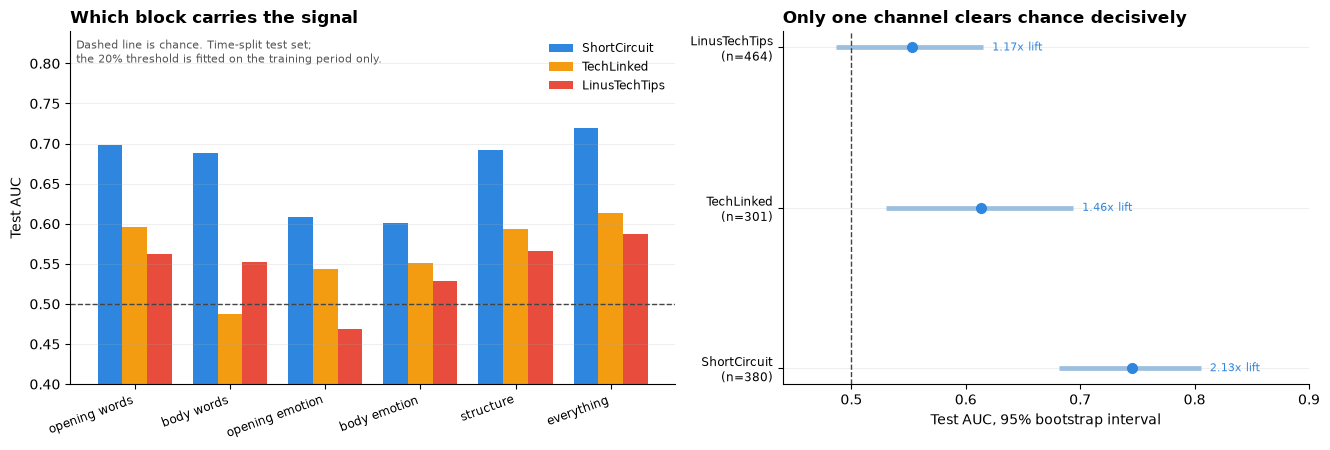

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13.4, 4.6), gridspec_kw={"width_ratios":[1.15,1]})

blocks = ["opening words","body words","opening emotion","body emotion","structure","everything"]
w, x = .26, np.arange(len(blocks))
COL = {"ShortCircuit":"#2E86DE","TechLinked":"#F39C12","LinusTechTips":"#E74C3C"}
for i, ch in enumerate(["ShortCircuit","TechLinked","LinusTechTips"]):
    if ch not in abl.index: continue
    ax[0].bar(x + (i-1)*w, abl.loc[ch, blocks], w, color=COL[ch], label=ch)
ax[0].axhline(.5, color="#444", ls="--", lw=1)
ax[0].set_xticks(x); ax[0].set_xticklabels(blocks, rotation=20, ha="right", fontsize=8.5)
ax[0].set_ylabel("Test AUC"); ax[0].set_ylim(.4, .84)
ax[0].set_title("Which block carries the signal", loc="left", weight="bold")
ax[0].legend(frameon=False, fontsize=8.5)
ax[0].text(.01,.98,"Dashed line is chance. Time-split test set;\nthe 20% threshold is fitted on the training period only.",
           transform=ax[0].transAxes, ha="left", va="top", fontsize=8.2, color="#555")

pf = perf.sort_values("auc")
y = np.arange(len(pf))[::-1]
ax[1].hlines(y, pf.lo, pf.hi, color="#9BbFdE", lw=3.4, zorder=2)
ax[1].plot(pf.auc, y, "o", color="#2E86DE", ms=7, zorder=3)
ax[1].axvline(.5, color="#444", ls="--", lw=1)
ax[1].set_yticks(y); ax[1].set_yticklabels([f"{c}\n(n={int(n)})" for c, n in
                                            zip(pf.index, pf.n_test)], fontsize=8.5)
ax[1].set_xlabel("Test AUC, 95% bootstrap interval")
ax[1].set_title("Only one channel clears chance decisively", loc="left", weight="bold")
for yi, (_, r) in zip(y, pf.iterrows()):
    ax[1].text(r.hi + .008, yi, f"{r.lift:.2f}x lift", va="center", fontsize=8.2, color="#2E86DE")
ax[1].set_xlim(.44, .90)
for a in ax: a.spines[["top","right"]].set_visible(False); a.grid(axis="y", alpha=.2)
plt.tight_layout(); plt.savefig(FIG/"content_model.png", bbox_inches="tight"); plt.show()

In [ ]:
# ── for Remotion ──────────────────────────────────────────────────────────────
# Exports two things per figure: a transparent PLATE (axes, ticks, labels, titles,
# reference lines — no data marks) and a JSON of the series plus the geometry needed
# to map data coordinates onto the plate in pixels.
#
# The plate is rebuilt from scratch rather than stripped from the original, so a
# reference line can never be removed by accident. Numbers still come only from here.
REM = FIG/"remotion"; REM.mkdir(exist_ok=True)

def plate_geometry(fig, axes):
    """Pixel box of each axes plus its data limits — everything Remotion needs."""
    w_px, h_px = fig.get_size_inches()*fig.dpi
    out = []
    for a in axes:
        p = a.get_position()
        out.append({
            "px": {"x": p.x0*w_px, "y": (1-p.y1)*h_px, "w": p.width*w_px, "h": p.height*h_px},
            "xlim": list(a.get_xlim()), "ylim": list(a.get_ylim()),
            "xscale": a.get_xscale(), "yscale": a.get_yscale(),
        })
    return {"figure_px": {"w": w_px, "h": h_px}, "dpi": fig.dpi, "axes": out}

def save_plate(fig, name, series):
    fig.savefig(REM/f"{name}_plate.png", bbox_inches=None, transparent=True)
    geo = plate_geometry(fig, fig.axes)
    (REM/f"{name}.json").write_text(json.dumps({**geo, "series": series}, indent=1))
    print(f"  {name}_plate.png  +  {name}.json   "
          f"({geo['figure_px']['w']:.0f}x{geo['figure_px']['h']:.0f}px, {len(series)} series)")

# ---- content_model, right panel: intervals that can open outward from the point ---
pf = perf.sort_values("auc")
series = [{"name": str(c), "color": "#2E86DE", "kind": "interval",
           "y": float(i), "point": float(r.auc), "lo": float(r.lo), "hi": float(r.hi),
           "label": f"{c} (n={int(r.n_test)})"}
          for i, (c, r) in zip(np.arange(len(pf))[::-1], pf.iterrows())]
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.axvline(.5, color="#444", ls="--", lw=1)
yy = np.arange(len(pf))[::-1]
ax.set_yticks(yy); ax.set_yticklabels([f"{c}\n(n={int(n)})" for c, n in
                                       zip(pf.index, pf.n_test)], fontsize=8.5)
ax.set_xlabel("Test AUC, 95% bootstrap interval")
ax.set_title("Only one channel clears chance decisively", loc="left", weight="bold")
ax.set_xlim(.44, .90); ax.set_ylim(-.6, len(pf)-.4)
ax.spines[["top","right"]].set_visible(False); ax.grid(axis="y", alpha=.2)
plt.tight_layout()
save_plate(fig, "content_model_right", series); plt.close(fig)

## 5. Commercial landing — and a correction to `06`

> ⚠️⚠️ **Two findings in this section were killed by `08`. Read `08` before citing anything here.**
>
> - **The Floatplane "single-month cliff" was a URL migration.** They moved outbound links onto
>   their own shortener, `lmg.gg`, in February 2023. Any mention of Floatplane runs 99.1% of
>   uploads in 2021 and **100% in 2026** — it never left. The chart in this section was measuring
>   a string rewrite.
> - **The affiliate decline was regex under-coverage.** Under a taxonomy built from a census of
>   every URL in the corpus, commercial outbound links run **100% in 2021 and 100% in 2026**.
>
> What survives: long-form storefront attachment at 99% (flat), and the Shorts result — which `08`
> confirms and sharpens.
>
> Left in place rather than rewritten, because the error and its correction are worth more together.



A model that predicts breakouts is only worth something if it attaches to a decision. The decision
available here is where the storefront link goes, which `06` measured as attachment rate.

**`06` got this wrong and this section fixes it.** That notebook reported blended attachment
falling from 98.2% in 2021 to 86.1% in 2025 and read it as the company withdrawing from its own
storefront. Splitting by format shows it is a composition effect, not a behaviour change.

In [25]:
dv = desc.merge(vids[["id","channel","date","views","format"]], on="id")
dv["yr"] = dv.date.dt.year
dv["fp"] = dv.description.str.contains(r"floatplane\.com", case=False, na=False)
dv["aff"] = dv.description.str.contains(r"amzn\.to|geni\.us|howl\.link|tag=", case=False, na=False)

print("Store-link attachment rate, split by format\n")
print((dv[dv.yr.between(2021, 2026)]
       .pivot_table(index="yr", columns="format", values="store", aggfunc="mean")*100).round(1).to_string())
print("\nUploads by format\n")
print(dv[dv.yr.between(2021, 2026)]
      .pivot_table(index="yr", columns="format", values="id", aggfunc="count", fill_value=0).to_string())

Store-link attachment rate, split by format

format  long_video  short
yr                       
2021          99.1   58.8
2022          99.5   57.1
2023          98.6   58.7
2024          98.8   58.1
2025          99.5    2.2
2026         100.0    0.0

Uploads by format

format  long_video  short
yr                       
2021           757     17
2022           784    119
2023           699     75
2024           661     43
2025           564     90
2026           313    109


> **Long-form attachment never moved.** 99.1% in 2021, 99.5% in 2025. The blended figure fell
> because Shorts — which carried links on only ~58% of uploads even at their peak, and 2.2% in
> 2025 — grew from 17 uploads a year to 90, and 109 in the first half of 2026 alone.
>
> This is the same error as the AI cluster in `05` and the 45-minute filter in `02`: an average
> taken across a heterogeneous mix, read as if the mix were constant. **Third time.** The pattern
> is specific enough now to name as a rule — before reporting any rate as a trend, split it by
> every dimension along which the denominator could have shifted.

### What the corrected picture shows instead

The real gap is not that links were removed from videos. It is that output is moving into a format
that never carried them, and that format is no longer trivial.

In [26]:
lv  = dv[dv.format == "long_video"]
sh  = dv[dv.format == "short"]

t = (lv[lv.yr.between(2021, 2025)].groupby("yr")
     .apply(lambda g: pd.Series({"uploads": len(g), "attach": g.store.mean(),
                                 "views_M": g.views.sum()/1e6,
                                 "exposed_M": g.loc[g.store, "views"].sum()/1e6}),
            include_groups=False))
print("Long-form only\n"); print(t.round(3).to_string())
b, e = t.loc[2021], t.loc[2025]
print(f"\n  2021 → 2025: attachment {b.attach:.1%} → {e.attach:.1%} (flat)")
print(f"               reach {b.views_M:.0f}M → {e.views_M:.0f}M ({e.views_M/b.views_M-1:+.0%})")
print(f"               store exposure {b.exposed_M:.0f}M → {e.exposed_M:.0f}M "
      f"({e.exposed_M/b.exposed_M-1:+.0%})")
print("\n  The store-exposure decline on long-form is the reach decline. Attachment adds nothing.")

s = (sh[sh.yr.between(2021, 2025)].groupby("yr")
     .apply(lambda g: pd.Series({"uploads": len(g), "attach": g.store.mean(),
                                 "views_M": g.views.sum()/1e6,
                                 "exposed_M": g.loc[g.store, "views"].sum()/1e6}),
            include_groups=False))
print("\n\nShorts\n"); print(s.round(3).to_string())
tot25 = dv[dv.yr == 2025].views.sum()/1e6
print(f"\n  2025: Shorts delivered {s.loc[2025,'views_M']:.0f}M views — "
      f"{s.loc[2025,'views_M']/tot25:.0%} of everything the network produced —")
print(f"        and {s.loc[2025,'exposed_M']:.1f}M of those carried a store link "
      f"({s.loc[2025,'attach']:.1%}).")
print(f"  2022: Shorts delivered {s.loc[2022,'views_M']:.0f}M views with "
      f"{s.loc[2022,'exposed_M']:.0f}M linked ({s.loc[2022,'attach']:.1%}).")

print("\n\nFloatplane, long-form only — the break survives the format split\n")
q = lv[lv.date.between("2022-11-01", "2023-05-31")].copy()
q["ym"] = q.date.dt.to_period("M")
print((q.groupby("ym")[["fp","store","aff"]].mean()*100).round(1).to_string())

Long-form only

      uploads  attach   views_M  exposed_M
yr                                        
2021    757.0   0.991  1087.289   1064.271
2022    784.0   0.995  1204.856   1186.928
2023    699.0   0.986   990.532    957.503
2024    661.0   0.988   777.862    767.845
2025    564.0   0.995   584.920    582.352

  2021 → 2025: attachment 99.1% → 99.5% (flat)
               reach 1087M → 585M (-46%)
               store exposure 1064M → 582M (-45%)

  The store-exposure decline on long-form is the reach decline. Attachment adds nothing.


Shorts

      uploads  attach  views_M  exposed_M
yr                                       
2021     17.0   0.588   21.147      5.102
2022    119.0   0.571  337.045    250.801
2023     75.0   0.587  133.101    110.508
2024     43.0   0.581   85.806     47.422
2025     90.0   0.022  205.304      9.385

  2025: Shorts delivered 205M views — 26% of everything the network produced —
        and 9.4M of those carried a store link (2.2%).
  2022: Shorts 

> **Three separate things, now correctly separated.**
>
> **1. Long-form store exposure fell 45%, and all of it is reach.** Attachment held at 99%. `06`'s
> decomposition into "reach −29% and attachment −12%" was an artefact; the honest version is that
> the storefront's exposure tracks reach one-for-one on long-form, with no offsetting decision.
>
> **2. Shorts are a real gap.** In 2022 Shorts delivered 337M views with 251M of them carrying a
> store link. In 2025 they delivered **205M views — 26% of everything the network produced — with
> 9M linked**. The format that is growing fastest is the one with no storefront attachment, and
> the company used to attach to it. Adding a line to a description costs nothing.
>
> **3. Floatplane and affiliate links did fall, and that is not composition.** On long-form alone,
> Floatplane goes from 89.5% of uploads in January 2023 to 1.7% in February — one month. Affiliate
> links fall from 96.8% in 2021 to 36.5% in 2025. Those are decisions.
>
> **What the model adds to this.** On ShortCircuit the model identifies a top quintile that
> contains 42% of breakouts against 20% at random. That is not a content instruction — it is a
> triage signal, and the decision it fits is exactly this one: which uploads are worth the
> merchandising attention. It is worth least on the flagship, where the model cannot beat chance
> at all, and most on the channel that is both content-sensitive and declining fastest.

## 6. What this notebook does not establish

**Prediction is not causation, and the gap here is wide.** The model finds that slower, longer
ShortCircuit videos with calmer titles tend to over-perform. It cannot say that slowing a video
down would make it over-perform. The plausible confounder is obvious: the videos worth spending
more time on are chosen before they are made, and the model may be reading that choice rather than
the pacing.

**Content is upstream of distribution, and this measures neither cleanly.** The rolling baseline
index is a view-based outcome, so what is being predicted is the joint effect of content on
click-through, on retention, and on how far the recommender pushes the result. Separating them
still needs click-through rate, average view duration and retention, which remain owner-only.
A 0.745 AUC says content carries signal about the joint outcome. It does not locate the signal.

**The hook is a character-position proxy.** `04` discarded the caption timings, so "first ninety
seconds" is really "first 1,250 characters" and the error varies with speaking rate. Anyone
repeating this should keep the `json3` timestamps.

**Auto-generated captions are not the video.** No thumbnail, no title card, no on-screen text, no
edit pace, no face. The single most important determinant of click-through — the thumbnail — is
entirely absent from every feature in this notebook.

**One threshold, one split date.** Top-20% at 2024-07-01. The ordering across channels is stable
under the block ablation, but the specific AUCs would move under other choices, and nothing here
tests that.

**Techquickie is absent** — 57 test videos after the blackout — and it is also the channel `06`
could not analyse by subject. Two different methods, same channel excluded for two different
reasons, which is worth saying out loud rather than letting it disappear into a footnote.

## 7 · The positive control as the deck draws it

Section 2 prints the control as three accuracies in a row. The talk needs it as a picture, and
a picture needs a floor: 94% is only a number until you can see what it is 94% *against*. Two
floors, because there are two honest ones — uniform guessing, and always naming the biggest
channel.

In [ ]:
# ── Slide 6's figure: the positive control, as three bars ─────────────────────
# Two baselines and the model, which is the argument of the control: 94% means nothing
# on its own. Guessing uniformly across four channels is 25% by construction, whatever
# the class sizes. Always naming the biggest channel does better than that, and it is
# the honest floor a classifier has to clear.
#
# PROVENANCE. All three numbers come from section 2 of this notebook, whose cell prints
# them and whose output is stored: "train 2,563 · test 1,202 · majority-class baseline
# 0.386", then "both  accuracy 0.942". They are carried across as literals rather than
# retrained, because the model needs the full feature stack (TF-IDF + SVD of the
# opening, VADER sentiment, structural features) and this cell is meant to be cheap.
#
# A standalone re-derivation of the test split from videos_clean.csv returns 1,419
# uploads and a 42.4% majority share, NOT 1,202 and 38.6%. The difference is section 2's
# further filtering of `m`. The figure follows section 2, because that is the split the
# model was actually trained and tested on, and quoting a baseline computed on a
# different set than the model would be comparing two things that never met.
import json, pathlib

REM = pathlib.Path("figures/remotion"); REM.mkdir(parents=True, exist_ok=True)
N_CHANNELS, N_TEST = 4, 1202
UNIFORM, MAJORITY, MODEL = 100 / N_CHANNELS, 38.6, 94.2

print(f"positive control · {N_TEST:,} test uploads across {N_CHANNELS} channels")
print(f"  guess at random (1 in {N_CHANNELS})          {UNIFORM:5.1f}%")
print(f"  always the biggest channel        {MAJORITY:5.1f}%")
print(f"  my model                          {MODEL:5.1f}%")

out = {"bar_width": 0.52, "n_test": N_TEST, "series": [
    {"name": "guess at random",            "color": "#39414E", "kind": "bar", "x": [0], "y": [UNIFORM]},
    {"name": "always the biggest channel", "color": "#7FB2E5", "kind": "bar", "x": [1], "y": [MAJORITY]},
    {"name": "my model",                   "color": "#4DA3FF", "kind": "bar", "x": [2], "y": [MODEL]},
]}
json.dump(out, open(REM/"positive_control.json", "w"), indent=1)
print(f"\nwrote {REM/'positive_control.json'}")


positive control · 1,202 test uploads across 4 channels
  guess at random (1 in 4)           25.0%
  always the biggest channel         38.6%
  my model                           94.2%

wrote figures/remotion/positive_control.json


## 8 · The hard job, in videos rather than in AUC

Slide 7 used to show the AUC intervals, and the speaker notes said not to say the word AUC out loud —
so the audience heard *76 picks, 32 breakouts, 15 without the model* while reading a chart of
something else. Both were right; they were not the same measurement.

This section writes the number the slide is spoken about. It recomputes nothing: `top20_hit` and
`base_rate` come straight out of `content_model_perf.csv`, written by section 2 above, and the only
arithmetic here is turning two rates into counts of videos out of the same 76 picks.

In [ ]:
import json, pathlib, pandas as pd

REM = FIG/"remotion"; REM.mkdir(exist_ok=True)
perf = pd.read_csv(DATA/"content_model_perf.csv").set_index("channel")
r = perf.loc["ShortCircuit"]

# k is the model's top 20% of the test set — the same slice for both bars, so the two
# numbers differ only in how the 76 were chosen. int(), not round(), to match section 2.
k        = int(r.n_test * .2)
hits     = round(k * r.top20_hit)      # breakouts among the model's 76
expected = round(k * r.base_rate)      # breakouts among any 76 taken at random

out = {
    "bar_width": 0.52,
    "n_test": int(r.n_test), "k": k,
    "series": [
        {"name": "76 picked at random", "color": "#7FB2E5", "kind": "bar",
         "x": [0], "y": [float(expected)]},
        {"name": "my model's top 76",   "color": "#4DA3FF", "kind": "bar",
         "x": [1], "y": [float(hits)]},
    ],
}
json.dump(out, open(REM/"hit_rate.json", "w"), indent=1)
print(f"test set {int(r.n_test)}, top 20% = {k} picks")
print(f"  model's 76:      {hits} breakouts  ({r.top20_hit:.1%})")
print(f"  any 76 at random: {expected} breakouts  ({r.base_rate:.1%} base rate)")
print(f"  lift {r.lift:.2f}x  ·  AUC {r.auc:.3f} [{r.lo:.3f}, {r.hi:.3f}] stays in the footnote")
